<style>
.markdown-content {
    direction: rtl;
    text-align: right;
}

.markdown-content pre {
    direction: ltr;
    text-align: left;
}

.markdown-content code {
    direction: ltr;
    text-align: left;
}
</style>

<div class="markdown-content">

# Correlation & Relationships — همبستگی و روابط

## تعریف

**Correlation** معیاری برای بررسی جهت و شدت رابطه بین دو متغیر است.

## انواع همبستگی

- **Positive Correlation:** افزایش یک متغیر معمولاً با افزایش متغیر دیگر همراه است.
- **Negative Correlation:** افزایش یک متغیر معمولاً با کاهش متغیر دیگر همراه است.
- **No Linear Correlation:** رابطه خطی مشخصی مشاهده نمی‌شود؛ ممکن است رابطه غیرخطی وجود داشته باشد.

## Pearson Correlation

ضریب همبستگی پیرسون با `r` نمایش داده می‌شود و بین `-1` و `+1` قرار دارد.

- `r ≈ +1`: رابطه خطی مثبت قوی.
- `r ≈ 0`: رابطه خطی ضعیف یا نامشخص.
- `r ≈ -1`: رابطه خطی منفی قوی.

پیرسون به داده‌های پرت حساس است و برای سنجش رابطه خطی کاربرد دارد.

## Spearman Correlation

همبستگی اسپیرمن بر اساس رتبه داده‌ها محاسبه می‌شود و برای بررسی روابط یکنواخت (Monotonic) مناسب است.

## ابزارهای بررسی رابطه

- `df.corr()`: محاسبه ماتریس همبستگی.
- `Series.corr()`: محاسبه همبستگی دو ستون.
- `spearmanr()`: محاسبه همبستگی اسپیرمن و مقدار P-value.
- `Scatter Plot`: مشاهده الگوی رابطه بین دو متغیر.
- `Heatmap`: نمایش بصری ماتریس همبستگی.

## نکات مهم

- **Correlation does not imply causation:** همبستگی علت و معلول را اثبات نمی‌کند.
- داده‌های پرت می‌توانند ضریب همبستگی را تغییر دهند.
- همبستگی نزدیک صفر، نبود هر نوع رابطه را تضمین نمی‌کند.
- همبستگی بالا بین Featureها ممکن است نشانه Multicollinearity باشد.
- مقدار P-value و اندازه نمونه برای تفسیر شواهد آماری اهمیت دارند.

<style>
.markdown-content {
    direction: rtl;
    text-align: right;
}

.markdown-content pre {
    direction: ltr;
    text-align: left;
}

.markdown-content code {
    direction: ltr;
    text-align: left;
}
</style>

<div class="markdown-content">

# تمرین ۱ — بررسی همبستگی با Pandas

## دیتاست

```python
import pandas as pd

df = pd.DataFrame({
    "marketing_spend": [100, 150, 200, 250, 300, 350, 400, 450],
    "revenue": [120, 180, 210, 280, 310, 390, 420, 480],
    "customer_satisfaction": [90, 85, 80, 75, 70, 65, 60, 55],
    "website_visits": [1000, 1200, 1500, 1700, 2100, 2400, 2700, 3000]
})
```

## وظایف

1. ماتریس همبستگی را با `df.corr()` محاسبه کن.
2. همبستگی بین `marketing_spend` و `revenue` را جداگانه محاسبه کن.
3. همبستگی بین `marketing_spend` و `customer_satisfaction` را محاسبه کن.
4. همبستگی بین `website_visits` و `revenue` را محاسبه کن.
5. نتایج را از نظر مثبت یا منفی بودن و شدت رابطه تفسیر کن.
6. توضیح بده چرا از این نتایج نمی‌توان رابطه علت و معلولی را قطعی دانست.

In [6]:
import pandas as pd

df = pd.DataFrame({
    "marketing_spend": [100, 150, 200, 250, 300, 350, 400, 450],
    "revenue": [120, 180, 210, 280, 310, 390, 420, 480],
    "customer_satisfaction": [90, 85, 80, 75, 70, 65, 60, 55],
    "website_visits": [1000, 1200, 1500, 1700, 2100, 2400, 2700, 3000]
})


# بخش ۱: محاسبه ماتریس همبستگی
print("\nبخش ۱: Correlation Matrix")

correlation_matrix = df.corr()

print(correlation_matrix)


# بخش ۲: همبستگی Marketing Spend و Revenue
print("\nبخش ۲: Marketing Spend vs Revenue")

marketing_revenue_corr = df["marketing_spend"].corr(
    df["revenue"]
)

print("Pearson Correlation:", marketing_revenue_corr)


# بخش ۳: همبستگی Marketing Spend و Customer Satisfaction
print("\nبخش ۳: Marketing Spend vs Customer Satisfaction")

marketing_satisfaction_corr = df["marketing_spend"].corr(
    df["customer_satisfaction"]
)

print("Pearson Correlation:", marketing_satisfaction_corr)


# بخش ۴: همبستگی Website Visits و Revenue
print("\nبخش ۴: Website Visits vs Revenue")

visits_revenue_corr = df["website_visits"].corr(
    df["revenue"]
)

print("Pearson Correlation:", visits_revenue_corr)


# بخش ۵: تفسیر خودکار نتایج
print("\nبخش ۵: تفسیر نتایج")


def interpret_correlation(value):
    if value >= 0.7:
        strength = "قوی"
    elif value >= 0.3:
        strength = "متوسط"
    elif value > -0.3:
        strength = "ضعیف"
    elif value > -0.7:
        strength = "متوسط"
    else:
        strength = "قوی"

    if value > 0:
        direction = "مثبت"
    elif value < 0:
        direction = "منفی"
    else:
        direction = "بدون جهت"

    return f"رابطه خطی {direction} و {strength}"


print(
    "Marketing Spend vs Revenue:",
    interpret_correlation(marketing_revenue_corr)
)

print(
    "Marketing Spend vs Customer Satisfaction:",
    interpret_correlation(marketing_satisfaction_corr)
)

print(
    "Website Visits vs Revenue:",
    interpret_correlation(visits_revenue_corr)
)


# بخش ۶: آیا همبستگی، رابطه علت و معلولی را ثابت می‌کند؟
print("\nبخش ۶: Correlation vs Causation")

print(
    "خیر؛ همبستگی به‌تنهایی رابطه علت و معلولی را ثابت نمی‌کند."
)

print(
    "ممکن است عوامل دیگری مانند فصل فروش، تخفیف‌ها "
    "یا شرایط بازار روی هر دو متغیر تأثیر بگذارند."
)


بخش ۱: Correlation Matrix
                       marketing_spend   revenue  customer_satisfaction  \
marketing_spend               1.000000  0.996643              -1.000000   
revenue                       0.996643  1.000000              -0.996643   
customer_satisfaction        -1.000000 -0.996643               1.000000   
website_visits                0.997530  0.993108              -0.997530   

                       website_visits  
marketing_spend              0.997530  
revenue                      0.993108  
customer_satisfaction       -0.997530  
website_visits               1.000000  

بخش ۲: Marketing Spend vs Revenue
Pearson Correlation: 0.9966427347156966

بخش ۳: Marketing Spend vs Customer Satisfaction
Pearson Correlation: -1.0

بخش ۴: Website Visits vs Revenue
Pearson Correlation: 0.9931075847256833

بخش ۵: تفسیر نتایج
Marketing Spend vs Revenue: رابطه خطی مثبت و قوی
Marketing Spend vs Customer Satisfaction: رابطه خطی منفی و قوی
Website Visits vs Revenue: رابطه خطی مثبت

<style>
.markdown-content {
    direction: rtl;
    text-align: right;
}

.markdown-content pre {
    direction: ltr;
    text-align: left;
}

.markdown-content code {
    direction: ltr;
    text-align: left;
}
</style>

<div class="markdown-content">

# تمرین ۲ — Pearson، Spearman و Scatter Plot

## دیتاست

```python
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

df = pd.DataFrame({
    "study_hours": [1, 2, 3, 4, 5, 6, 7, 8],
    "exam_score": [45, 50, 54, 62, 68, 75, 85, 95]
})
```

## وظایف

1. همبستگی پیرسون بین `study_hours` و `exam_score` را محاسبه کن.
2. همبستگی اسپیرمن را با `spearmanr()` محاسبه کن.
3. مقدار `P-value` اسپیرمن را چاپ کن.
4. با `plt.scatter()` نمودار پراکندگی رسم کن.
5. توضیح بده آیا در این نمونه رابطه مثبت مشاهده می‌شود یا خیر.
6. توضیح بده آیا این داده‌ها به‌تنهایی ثابت می‌کنند افزایش ساعات مطالعه علت افزایش نمره است یا خیر.

Pearson Correlation: 0.9907764124037717
Spearman Correlation: 1.0
P-value: 0.0


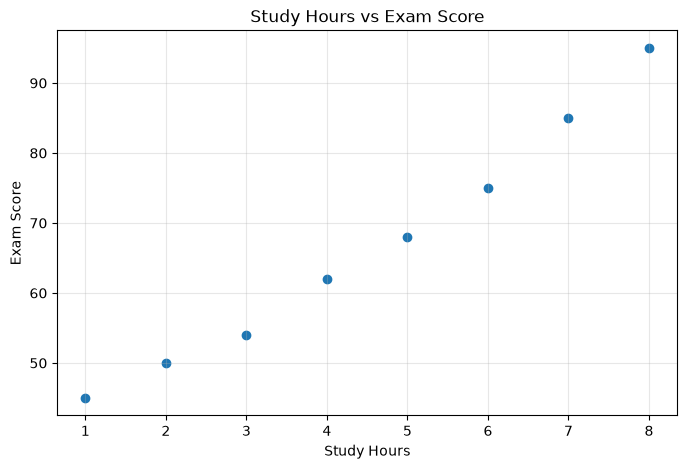


Interpretation:
هر دو ضریب همبستگی مثبت و نزدیک به 1 هستند.
بنابراین، بین ساعات مطالعه و نمره امتحان رابطه مثبت و قوی وجود دارد.
اما همبستگی به‌تنهایی رابطه علت و معلولی را اثبات نمی‌کند.


In [13]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import spearmanr

df = pd.DataFrame({
    "study_hours": [1, 2, 3, 4, 5, 6, 7, 8],
    "exam_score": [45, 50, 54, 62, 68, 75, 85, 95]
})

# 1. Pearson Correlation
pearson_corr = df["study_hours"].corr(df["exam_score"])
print("Pearson Correlation:", pearson_corr)

# 2. Spearman Correlation
spearman_corr, p_value = spearmanr(
    df["study_hours"],
    df["exam_score"]
)

print("Spearman Correlation:", spearman_corr)
print("P-value:", p_value)

# 3. Scatter Plot
plt.figure(figsize=(8, 5))
plt.scatter(df["study_hours"], df["exam_score"])

plt.title("Study Hours vs Exam Score")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.grid(True, alpha=0.3)

plt.show()

# 4. Interpretation
print("\nInterpretation:")
print("هر دو ضریب همبستگی مثبت و نزدیک به 1 هستند.")
print("بنابراین، بین ساعات مطالعه و نمره امتحان رابطه مثبت و قوی وجود دارد.")
print("اما همبستگی به‌تنهایی رابطه علت و معلولی را اثبات نمی‌کند.")